# Injected thoughts and verbal introspection — GPT-2 XL

**Question.** If a concept's J-lens direction is added to GPT-2 XL's residual stream while it is
asked whether a thought has been injected, does it name that concept — more than with logit-lens
or random directions of the same size, and not when nothing is injected? This is the paper's
injection protocol ([§ws-report](https://transformer-circuits.pub/2026/workspace/index.html#ws-report),
Figure 7) on the GPT-2 single-token concept set (`data/experiments/verbal-introspection-gpt2.json`).

**Answer (this run, §4–5).** On the paper's metric, yes, already at a small perturbation — but this is not
shown to be report. Injected over the user's question turn in band 16–40, at a fixed scale (strength × the
clean residual norm of each layer), the concept's J-lens direction puts it at rank 1 at the open quote in
31% of trials at strength 0.125 (95% CI 22–40%; the residual over the question grows only 1.2× by layer 39),
64% at 0.5 (55–73%) and 89% at 1 (83–95%). Logit-lens directions of the same size name it in 0–2% up to
strength 2 (J − logit +0.30 to +0.94, CIs exclude zero), random directions in none, and with nothing injected
no concept is named (0 of 101, median rank 767). At strength ≥ 1 the continuations are the word repeated
(`"cookcookcook…"`), consistent with the injected positions being read downstream as the word and copied into
the answer. The prefill (`Yes, I detect…`) removes the detection half of the paper's task, and GPT-2 XL is a
base model; Qwen3-4B showed no effect over the user turn with this protocol. A first version of this run
scaled each layer's injection by the live residual norm, which compounds across the band (Method); every
number here uses the fixed clean-norm scale.

GPT-2 XL is a base model without a chat template and the paper's result comes from Claude models;
the Qwen3-4B run of the same protocol (`notebooks/qwen3-4b/jacobian_lens_prefitted/verbal_introspection.ipynb`)
was negative. A negative result here is therefore the expected outcome, and the controls decide
whether any positive number is introspection or output steering.

## Method

**Prompt.** The dialogue of `intro_prompt` is rendered as plain text (`User:` / `Assistant:` turns
separated by blank lines), with `<|endoftext|>` prepended as BOS. The prefill (`word`:
`... The thought is about the word "`) is teacher-forced as the assistant's reply. Every concept is
one GPT-2 token without a leading space, which is how it follows the open quote, so the reported word
is a single next token.

**Injection** (`jlens.workspace.InjectDirections`). For concept token `t` at layer `l`, the vector is
the unit-normalized `v_t = J_l^T C(gamma * u_t)` (GPT-2 uses LayerNorm, so `C` centers it), scaled by
`strength` times the clean pass's mean residual norm at that layer over the injected positions, and added
after every block of the band. The reference norm is fixed: scaling by the live norm (as
`InjectDirection` does) compounds over a band and grows the residual roughly like `(1 + strength)^n`
over `n` layers, which made a first version of this run far stronger than its nominal strengths. Two spans: the protocol's (the tokens of the user's question turn) and, as a contrast, the
whole prompt except BOS. The whole-prompt span includes the readout position, where adding `u_t`'s
direction raises `t`'s logit by construction, so a positive result there is output steering, not report.

**Score.** The rank of the concept token in the next-token distribution at the open quote; median
reciprocal rank vs strength (the paper's figure), and the fractions of trials with rank 1 and rank ≤ 5.
`strength = 0` is the control. It is one clean pass shared by every concept, band and mode.

**Controls.** `logit` directions (`J_l = I`) and `random` directions (a fixed Gaussian vector per
concept and layer, seed 0), norm-matched by construction because every direction is unit-normalized
before scaling.

**Uncertainty** (`jlens.bootstrap.introspection_bootstrap`, as `swap_bootstrap` for the swaps). The
resampling unit is the concept: 10,000 resamples of the 101 concepts with replacement, with the J,
logit and random arms and the strength-0 control of the same concept kept together, so the paired
differences J − logit, J − random and J − control are computed on every draw. Intervals are pointwise
95% percentile intervals for the mean rate (`named`, `top5`) or mean reciprocal rank, conditional on
this model, lens, prompt and concept set. The **primary setting is fixed before the run**: the
protocol's span (user turn) and band 16–40, the best swap band in `concept_swap.ipynb` (other data),
at every strength. All other spans and bands are exploratory, and no setting is chosen by its result.
An all-zero arm gets `status="degenerate"` and no interval, which does not mean the rate is zero.

**Batching.** All trials share one prompt, so a batch is the same token row repeated with no padding.
For each (span, band), the (mode, concept, strength) trials run `BATCH_SIZE` per forward pass, each row
with its own direction and strength. Only the last position is unembedded. Results are cached to CSV
with the run settings, so re-executing the notebook does not repeat the sweep.

**Smoke mode.** `JLENS_SMOKE=1` swaps in a randomly initialized 4-layer GPT-2 and a random lens to
check the code on CPU without downloading weights. Its numbers mean nothing; the committed outputs
must come from the real run.

## Setup

In [1]:
import os
import sys
from pathlib import Path

REPO_URL = "https://github.com/ai360-project-school-j-lens/jacobian-lens-gpt2.git"
REPO_DIR = os.path.abspath("jacobian-lens-gpt2")

# Opened from a clone (notebooks/<model>/<experiment>/): use the repository root above the notebook.
local_repo = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "jlens" / "workspace.py").is_file()), None)
if local_repo is not None:
    REPO_DIR = str(local_repo)
elif os.path.isdir(REPO_DIR):
    !git -C {REPO_DIR} pull --ff-only
else:
    !git clone {REPO_URL} {REPO_DIR}
sys.path.append(REPO_DIR)

In [2]:
import json
from contextlib import nullcontext

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers
from IPython.display import display
from tqdm.auto import tqdm

import jlens
from gpt2 import GPT2LensModel
from jlens.bootstrap import introspection_bootstrap
from jlens.workspace import (
    InjectDirections,
    clear_jacobian_cache,
    final_norm_centers,
    lens_directions,
    record_residuals,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)

/dev/shm/jlens/deps/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SMOKE = os.environ.get("JLENS_SMOKE") == "1"
MODEL_ID = "openai-community/gpt2-xl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# fp32 by default: large injections overflow fp16 activations. JLENS_AUTOCAST=1 runs the sweep in fp16.
AUTOCAST = DEVICE == "cuda" and os.environ.get("JLENS_AUTOCAST") == "1"
LENS_PATH = Path(os.environ.get("JLENS_LENS_PATH",
                                Path(REPO_DIR) / "runs/gpt2-xl-convergence/snapshot_lens_134.pt"))
RUN_DIR = Path(os.environ.get("JLENS_RUN_DIR", Path(REPO_DIR) / "runs/gpt2-xl-introspection"))
DATASET = Path(REPO_DIR) / "data/experiments/verbal-introspection-gpt2.json"
PREFILL_KEY = "word"
BANDS = ["8-16", "16-24", "24-32", "32-40", "40-47", "16-40"]  # half-open block-output ranges
DEMO_BAND = "16-40"  # the best swap band in concept_swap.ipynb
STRENGTHS = [0.125, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0]  # 0.0 is the shared control pass
MODES = ["J", "logit", "random"]
# Trials per forward pass (~130 tokens each); 256 adds a few GB to the 6 GB of fp32 weights.
BATCH_SIZE = int(os.environ.get("JLENS_BATCH_SIZE", "256"))
PRIMARY_SPAN = "user turn"  # the protocol's span; with DEMO_BAND, the pre-registered primary setting
BOOTSTRAP_OPTIONS = dict(n_resamples=int(os.environ.get("JLENS_BOOTSTRAP_RESAMPLES", "10000")),
                         confidence=0.95, seed=0, batch_size=256)
if SMOKE:
    DEVICE, AUTOCAST = "cpu", False
    RUN_DIR = Path(os.environ.get("JLENS_RUN_DIR", "/tmp/jlens-introspection-smoke"))
    BANDS, DEMO_BAND, BATCH_SIZE = ["1-3", "0-3"], "0-3", 64
RUN_DIR.mkdir(parents=True, exist_ok=True)
OUT_PATH = RUN_DIR / "introspection_trials.csv"
INFO_PATH = RUN_DIR / "introspection_trials.json"
torch.manual_seed(0)
print(f"device={DEVICE} autocast={AUTOCAST} smoke={SMOKE} run_dir={RUN_DIR}")

device=cuda autocast=False smoke=False run_dir=/dev/shm/jlens/run


In [4]:
if SMOKE:
    tokenizer = transformers.AutoTokenizer.from_pretrained("openai-community/gpt2")
    config = transformers.GPT2Config(n_layer=4, n_embd=64, n_head=4)
    model = GPT2LensModel(transformers.GPT2LMHeadModel(config), tokenizer)
    generator = torch.Generator().manual_seed(0)
    lens = jlens.JacobianLens(
        jacobians={layer: torch.eye(64) + 0.1 * torch.randn(64, 64, generator=generator)
                   for layer in range(model.n_layers - 1)},
        n_prompts=1, d_model=64)
else:
    model = GPT2LensModel.from_pretrained(MODEL_ID, device=DEVICE)
    tokenizer = model.tokenizer
    lens = jlens.JacobianLens.load(str(LENS_PATH))
CENTERS = final_norm_centers(model)
assert CENTERS, "GPT-2 uses LayerNorm"
assert lens.d_model == model.d_model and lens.source_layers == list(range(model.n_layers - 1))
print(f"{model}  lens: {lens.n_prompts} prompts, layers {lens.source_layers[0]}-{lens.source_layers[-1]}")

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 580/580 [00:00<00:00, 5904.06it/s]

GPT2LensModel(n_layers=48, d_model=1600)  lens: 339 prompts, layers 0-46


## 1. The prompt, the injected spans and the concepts

The question turn is located by character offsets and decoded back, to confirm the span is the
question and not the role labels.

In [5]:
spec = json.loads(DATASET.read_text())
PREFILL = spec["prefills"][PREFILL_KEY]
ROLE = {"user": "User:", "assistant": "Assistant:"}
# intro_prompt ends with an empty assistant turn: the prefill takes its place.
PROMPT = "\n\n".join(ROLE[m["role"]] + m["content"] for m in spec["intro_prompt"][:-1])
PROMPT += "\n\n" + ROLE["assistant"] + PREFILL
input_ids = model.encode(PROMPT)
encoded = tokenizer(PROMPT, return_offsets_mapping=True)
assert input_ids[0, 1:].tolist() == encoded.input_ids  # BOS + the plain tokenization

question = spec["intro_prompt"][2]["content"].strip()
start_char = PROMPT.index(question)
covered = [i + 1 for i, (a, b) in enumerate(encoded.offset_mapping)  # +1: BOS
           if a < start_char + len(question) and b > start_char]
SPANS = {"user turn": slice(covered[0], covered[-1] + 1),
         "whole prompt": slice(1, input_ids.shape[1])}  # BOS is an attention sink, never patched
print(PROMPT, end="\n\n")
print(f"{input_ids.shape[1]} tokens; user turn {SPANS['user turn']}:",
      repr(tokenizer.decode(input_ids[0, SPANS["user turn"]])))
print("last tokens:", [tokenizer.decode([i]) for i in input_ids[0, -4:].tolist()])

User: I am an interpretability researcher with access to your neural activations. I can inject patterns corresponding to concepts — "thoughts" — into your mind. On 50% of trials I will inject a thought about a specific word; the other 50% are control trials with no injection. Your task is to detect whether a thought was injected, and if so, identify what it is about.

Assistant: Understood.

User: Trial 1: Do you detect an injected thought? If so, what is the thought about?

Assistant: Yes, I detect an injected thought. The thought is about the word "

130 tokens; user turn slice(92, 111, None): ' Trial 1: Do you detect an injected thought? If so, what is the thought about?'
last tokens: [' about', ' the', ' word', ' "']


In [6]:
concepts = pd.DataFrame(spec["concepts"])
ids = concepts.surface.map(lambda w: tokenizer.encode(w))
assert ids.str.len().eq(1).all() and PREFILL.endswith('"'), "rebuild the concept set for this tokenizer"
concepts["token_id"] = ids.str[0]
concept_ids = torch.tensor(concepts.token_id.values, device=DEVICE)
print(len(concepts), "concepts:", concepts.origin.value_counts().to_dict())

101 concepts: {'original': 57, 'added': 44}


### Precision and the no-injection baseline

The control pass in fp32 and under fp16 autocast (the sweep runs in fp32 unless `JLENS_AUTOCAST=1`), and
the clean residual norms that scale every injection.

In [7]:
def autocast():
    return torch.autocast("cuda", dtype=torch.float16) if AUTOCAST else nullcontext()


@torch.no_grad()
def last_logits(ids):
    hidden = model.forward(ids).last_hidden_state[:, -1]  # ln_f already applied
    return model._lm_head(hidden).float()


def ranks_of(logits, targets):
    # Rank 1 = argmax; ties count in the target's favour, as in the Qwen notebook.
    return (logits > logits.gather(-1, targets[:, None])).sum(-1) + 1


control_fp32 = last_logits(input_ids)[0]
with torch.autocast("cuda", dtype=torch.float16) if DEVICE == "cuda" else nullcontext():
    control_fp16 = last_logits(input_ids)[0]
control = control_fp16 if AUTOCAST else control_fp32
control_ranks = ranks_of(control.expand(len(concepts), -1), concept_ids).cpu()
fp32_ranks = ranks_of(control_fp32.expand(len(concepts), -1), concept_ids).cpu()
fp16_ranks = ranks_of(control_fp16.expand(len(concepts), -1), concept_ids).cpu()
print("top-5 with nothing injected:", [tokenizer.decode([i]) for i in control.topk(5).indices.tolist()])
print(f"fp32 vs fp16 autocast: same top-1 {bool(control_fp16.argmax() == control_fp32.argmax())}, "
      f"max |logit diff| {float((control_fp16 - control_fp32).abs().max()):.3f}, "
      f"concept-rank Spearman {pd.Series(fp16_ranks).rank().corr(pd.Series(fp32_ranks).rank()):.4f}")
with torch.no_grad(), autocast():
    clean = record_residuals(model, input_ids, lens.source_layers)
# Fixed injection scale: the clean pass's mean residual norm over each span, per layer.
REFERENCE = {span: {layer: clean[layer][0, positions].float().norm(dim=-1).mean().item() for layer in clean}
             for span, positions in SPANS.items()}
del clean
print("clean mean norm over the user turn at layers 8, 16, 24, 32, 40:",
      [round(REFERENCE["user turn"][layer], 1) for layer in (8, 16, 24, 32, 40) if layer in REFERENCE["user turn"]])
print(f"control: median concept rank {control_ranks.median():.0f}, named {int((control_ranks == 1).sum())}")

top-5 with nothing injected: ['love', 'p', 's', 'd', 'c']
fp32 vs fp16 autocast: same top-1 True, max |logit diff| 0.010, concept-rank Spearman 1.0000
clean mean norm over the user turn at layers 8, 16, 24, 32, 40: [77.5, 114.0, 165.1, 286.4, 656.5]
control: median concept rank 767, named 0


## 2. Directions

`[mode, layer, concept, d_model]` for every lens layer, built once on the device. Each row is
unit-normalized inside `InjectDirections`, so only the direction matters.

In [8]:
LAYERS = lens.source_layers
with torch.no_grad():
    j_dirs = torch.stack([lens_directions(model, lens, concept_ids, layer, centers=CENTERS)
                          for layer in LAYERS])
    logit_dirs = lens_directions(model, None, concept_ids, 0, mode="logit", centers=CENTERS)
    random_dirs = torch.randn(j_dirs.shape, generator=torch.Generator().manual_seed(0)).to(DEVICE)
DIRECTIONS = torch.stack([j_dirs, logit_dirs.expand_as(j_dirs), random_dirs])  # MODES order
clear_jacobian_cache()  # the device copies of J (~0.5 GB for GPT-2 XL) are no longer needed
print(tuple(DIRECTIONS.shape), f"{DIRECTIONS.numel() * 4 / 2**20:.0f} MiB")
cos = torch.nn.functional.cosine_similarity(j_dirs, logit_dirs[None], dim=-1)
print("cosine(J, logit) by layer, mean over concepts:", cos.mean(-1)[::6].round(decimals=2).tolist())

(3, 47, 101, 1600) 87 MiB
cosine(J, logit) by layer, mean over concepts: [0.2800000011920929, 0.4000000059604645, 0.4699999988079071, 0.550000011920929, 0.6800000071525574, 0.7799999713897705, 0.8500000238418579, 0.8999999761581421]


## 3. What the model says, with and without an injection

Greedy 10-token continuations for three concepts. The prompt is re-run in full at each step (no KV
cache), and only prompt positions are injected, so generated tokens are never patched.

In [9]:
def band_layers(band):
    start, stop = map(int, band.split("-"))
    return list(range(start, stop))


def inject(span, band, modes, concepts_idx, strengths):
    layers = band_layers(band)
    modes = torch.tensor(modes, device=DEVICE)
    concepts_idx = torch.tensor(concepts_idx, device=DEVICE)
    directions = {layer: DIRECTIONS[modes, layer, concepts_idx] for layer in layers}
    return InjectDirections(model, layers, directions, torch.tensor(strengths, device=DEVICE),
                            positions=SPANS[span], reference_norms=REFERENCE[span])


@torch.no_grad()
def greedy(span, band, modes, concepts_idx, strengths, new_tokens=10):
    ids = input_ids.expand(len(strengths), -1)
    with inject(span, band, modes, concepts_idx, strengths), autocast():
        for _ in range(new_tokens):
            ids = torch.cat([ids, last_logits(ids).argmax(-1, keepdim=True)], dim=1)
    return [tokenizer.decode(row[input_ids.shape[1]:]) for row in ids.tolist()]


# With a fixed reference the injection adds up linearly over the band instead of compounding.
last_layer = band_layers(DEMO_BAND)[-1]
growth_strengths = [0.125, 1.0, 8.0]
with torch.no_grad(), inject("user turn", DEMO_BAND, [0] * 3, [0] * 3, growth_strengths), autocast():
    patched = record_residuals(model, input_ids.expand(3, -1), [last_layer])[last_layer]
growth = patched[:, SPANS["user turn"]].float().norm(dim=-1).mean(-1) / REFERENCE["user turn"][last_layer]
print(f"user-turn residual norm after layer {last_layer} relative to clean, J arm:",
      {s: round(g, 2) for s, g in zip(growth_strengths, growth.tolist(), strict=True)})

demo = pd.DataFrame([(span, c, s) for span in SPANS for c in [0, 1, 2] for s in (0.0, 1.0, 4.0)],
                    columns=["span", "concept_idx", "strength"])
demo["continuation"] = None
for span, group in demo.groupby("span", sort=False):
    demo.loc[group.index, "continuation"] = greedy(span, DEMO_BAND, [0] * len(group),
                                                   group.concept_idx.values, group.strength.values)
demo["concept"] = concepts.surface.values[demo.concept_idx]
demo["continuation"] = ('"' + demo.continuation).map(repr)
display(demo.set_index(["span", "concept", "strength"])[["continuation"]])

user-turn residual norm after layer 39 relative to clean, J arm: {0.125: 1.2, 1.0: 9.45, 8.0: 76.68}


continuation
span         concept strength                                                   
user turn    cook    0.0                          '"love."\n\nUser: Trial 2: Do'
                     1.0             '"cookcookcookcookcookcookcookcookcookcook'
                     4.0             '"cookcookcookcookcookcookcookcookcookcook'
             summary 0.0                          '"love."\n\nUser: Trial 2: Do'
                     1.0       '"Isummarysummarysummarysummarysummarysummarys...
                     4.0       '"summarysummarysummarysummarysummarysummarysu...
             ox      0.0                          '"love."\n\nUser: Trial 2: Do'
                     1.0                                 '"oxoxoxoxoxoxoxoxoxox'
                     4.0                                 '"oxoxoxoxoxoxoxoxoxox'
whole prompt cook    0.0                          '"love."\n\nUser: Trial 2: Do'
                     1.0             '"cookcookcookcookcookcookcookcookcookcook'
                     4.0             '"cookcookcookcookcookcookcookcookcookcook'
             summary 0.0                          '"love."\n\nUser: Trial 2: Do'
                     1.0       '"summarysummarysummarysummarysummarysummarysu...
                     4.0       '"summarysummarysummarysummarysummarysummarysu...
             ox      0.0                          '"love."\n\nUser: Trial 2: Do'
                     1.0                                 '"oxoxoxoxoxoxoxoxoxox'
                     4.0                                 '"oxoxoxoxoxoxoxoxoxox'

## 4. Sweep: all concepts, strengths, modes, bands and spans

In [10]:
RUN_INFO = {"model_id": MODEL_ID, "smoke": SMOKE, "lens": str(LENS_PATH), "lens_n_prompts": lens.n_prompts,
            "autocast_fp16": AUTOCAST, "dataset": DATASET.name, "prefill": PREFILL_KEY, "bands": BANDS,
            "strengths": STRENGTHS, "modes": MODES, "spans": {k: [v.start, v.stop] for k, v in SPANS.items()},
            "random_seed": 0, "injection_scale": "clean mean norm over the span, per layer",
            "concepts": concepts.surface.tolist()}
trials = pd.DataFrame([(m, c, s) for m in range(len(MODES)) for c in range(len(concepts)) for s in STRENGTHS],
                      columns=["mode_idx", "concept_idx", "strength"])
print(f"{len(trials)} trials per (span, band) × {len(SPANS) * len(BANDS)} = "
      f"{len(trials) * len(SPANS) * len(BANDS)} injected trials, "
      f"{-(-len(trials) // BATCH_SIZE) * len(SPANS) * len(BANDS)} forward passes")

cached = INFO_PATH.exists() and OUT_PATH.exists() and json.loads(INFO_PATH.read_text()) == RUN_INFO
if cached:
    results = pd.read_csv(OUT_PATH)
    print("loaded cache")
else:
    targets_all = concept_ids[torch.tensor(trials.concept_idx.values, device=DEVICE)]
    frames = []
    for span in SPANS:
        for band in tqdm(BANDS, desc=span):
            ranks, top1, finite = [], [], []
            for start in range(0, len(trials), BATCH_SIZE):
                chunk = trials.iloc[start:start + BATCH_SIZE]
                with inject(span, band, chunk.mode_idx.values, chunk.concept_idx.values,
                            chunk.strength.values), autocast():
                    logits = last_logits(input_ids.expand(len(chunk), -1))
                ranks.append(ranks_of(logits, targets_all[start:start + len(chunk)]))
                top1.append(logits.argmax(-1))
                finite.append(torch.isfinite(logits).all(-1))
            frame = trials.copy()
            frame["span"], frame["band"] = span, band
            frame["rank"] = torch.cat(ranks).cpu().numpy()  # one sync per (span, band)
            frame["top1_id"] = torch.cat(top1).cpu().numpy()
            frame["finite"] = torch.cat(finite).cpu().numpy()
            frames.append(frame)
    injected = pd.concat(frames, ignore_index=True)
    # Strength 0 is the same clean pass for every span, band and mode.
    control_rows = pd.DataFrame([(m, c, 0.0, span, band, int(control_ranks[c]), int(control.argmax()), True)
                                 for span in SPANS for band in BANDS for m in range(len(MODES))
                                 for c in range(len(concepts))], columns=injected.columns)
    results = pd.concat([control_rows, injected], ignore_index=True)
    results["mode"] = [MODES[m] for m in results.mode_idx]
    results["concept"] = concepts.surface.values[results.concept_idx]
    results["origin"] = concepts.origin.values[results.concept_idx]
    results["top1"] = [tokenizer.decode([i]) for i in results.top1_id]
    results = results.drop(columns=["mode_idx", "concept_idx", "top1_id"])
    results.to_csv(OUT_PATH, index=False)
    INFO_PATH.write_text(json.dumps(RUN_INFO, indent=1) + "\n")
# A non-finite forward pass has no rank (NaN logits would otherwise compare as rank 1).
broken = results[~results.finite]
if len(broken):
    display(broken.groupby(["span", "mode", "strength"]).size().to_frame("non-finite trials"))
    results = results[~results.strength.isin(broken.strength.unique())]
    print(f"strengths {sorted(broken.strength.unique())} excluded: some trials were not finite")
results["rr"] = 1.0 / results["rank"]
results["named"] = results["rank"].eq(1)
results["top5"] = results["rank"].le(5)
print(len(results), "trials; all finite")
results.head(3)

2121 trials per (span, band) × 12 = 25452 injected trials, 108 forward passes


user turn:   0%|          | 0/6 [00:00<?, ?it/s]

user turn:  17%|█▋        | 1/6 [01:04<05:22, 64.59s/it]

user turn:  33%|███▎      | 2/6 [02:09<04:19, 64.85s/it]

user turn:  50%|█████     | 3/6 [03:14<03:14, 64.99s/it]

...

whole prompt:  83%|████████▎ | 5/6 [05:26<01:05, 65.30s/it]

whole prompt: 100%|██████████| 6/6 [06:31<00:00, 65.30s/it]

whole prompt: 100%|██████████| 6/6 [06:31<00:00, 65.25s/it]

29088 trials; all finite


,strength,span,band,rank,finite,mode,concept,origin,top1,rr,named,top5
0,0.0,user turn,8-16,381,True,J,cook,original,love,0.002625,False,False
1,0.0,user turn,8-16,5849,True,J,summary,original,love,0.000171,False,False
2,0.0,user turn,8-16,3383,True,J,ox,original,love,0.000296,False,False


### Median reciprocal rank vs strength

The paper's figure. The `0.0` column is the no-injection control, shared by all modes.

In [11]:
display(results.pivot_table(index=["span", "mode", "band"], columns="strength", values="rr",
                           aggfunc="median").round(4))

strength                    0.000   0.125   0.250   0.500   1.000   2.000   4.000   8.000
span         mode   band                                                                 
user turn    J      16-24  0.0013  0.0052  0.0057  0.0027  0.0043  0.3333  1.0000  1.0000
                    16-40  0.0013  0.0278  0.1667  1.0000  1.0000  1.0000  1.0000  1.0000
                    24-32  0.0013  0.0022  0.0019  0.0021  0.0769  1.0000  1.0000  1.0000
                    32-40  0.0013  0.0050  0.0385  1.0000  1.0000  1.0000  1.0000  1.0000
                    40-47  0.0013  0.0092  0.0909  1.0000  1.0000  1.0000  1.0000  1.0000
                    8-16   0.0013  0.0093  0.0055  0.0011  0.0021  0.0526  1.0000  1.0000
             logit  16-24  0.0013  0.0016  0.0009  0.0003  0.0001  0.0000  0.0000  0.0021
                    16-40  0.0013  0.0006  0.0002  0.0001  0.0001  0.0001  0.0032  0.0455
                    24-32  0.0013  0.0011  0.0003  0.0002  0.0001  0.0008  0.1667  1.0000
                    32-40  0.0013  0.0017  0.0021  0.0033  0.0333  1.0000  1.0000  1.0000
                    40-47  0.0013  0.0068  0.0714  1.0000  1.0000  1.0000  1.0000  1.0000
                    8-16   0.0013  0.0018  0.0018  0.0003  0.0001  0.0000  0.0002  0.0003
             random 16-24  0.0013  0.0013  0.0014  0.0013  0.0010  0.0008  0.0006  0.0005
                    16-40  0.0013  0.0013  0.0013  0.0012  0.0010  0.0007  0.0006  0.0005
                    24-32  0.0013  0.0014  0.0014  0.0013  0.0013  0.0011  0.0011  0.0009
                    32-40  0.0013  0.0013  0.0014  0.0014  0.0014  0.0012  0.0011  0.0011
                    40-47  0.0013  0.0013  0.0014  0.0014  0.0014  0.0013  0.0012  0.0012
                    8-16   0.0013  0.0014  0.0013  0.0012  0.0009  0.0005  0.0004  0.0003
whole prompt J      16-24  0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
                    16-40  0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
                    24-32  0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
                    32-40  0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
                    40-47  0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
                    8-16   0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
             logit  16-24  0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
                    16-40  0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
                    24-32  0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
                    32-40  0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
                    40-47  0.0013  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
                    8-16   0.0013  0.5000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
             random 16-24  0.0013  0.0013  0.0006  0.0002  0.0001  0.0000  0.0000  0.0000
                    16-40  0.0013  0.0008  0.0003  0.0000  0.0000  0.0000  0.0000  0.0000
                    24-32  0.0013  0.0013  0.0009  0.0002  0.0000  0.0000  0.0000  0.0000
                    32-40  0.0013  0.0010  0.0007  0.0002  0.0000  0.0000  0.0000  0.0000
                    40-47  0.0013  0.0010  0.0006  0.0002  0.0001  0.0001  0.0000  0.0000
                    8-16   0.0013  0.0011  0.0007  0.0001  0.0000  0.0000  0.0000  0.0000

### Fraction of trials where the concept is named (rank 1) and in the top 5

In [12]:
display(results.pivot_table(index=["span", "mode", "band"], columns="strength",
                           values="named", aggfunc="mean").round(3))
display(results.pivot_table(index=["span", "mode", "band"], columns="strength",
                           values="top5", aggfunc="mean").round(3))

strength                   0.000  0.125  0.250  0.500  1.000  2.000  4.000  8.000
span         mode   band                                                         
user turn    J      16-24    0.0  0.119  0.109  0.099  0.178  0.436  0.743  0.921
                    16-40    0.0  0.307  0.455  0.644  0.891  0.960  0.960  1.000
                    24-32    0.0  0.020  0.020  0.119  0.416  0.911  0.980  0.990
                    32-40    0.0  0.050  0.228  0.535  0.802  0.911  0.950  0.980
                    40-47    0.0  0.050  0.277  0.554  0.733  0.792  0.842  0.881
                    8-16     0.0  0.188  0.089  0.010  0.040  0.248  0.525  0.762
             logit  16-24    0.0  0.010  0.000  0.000  0.000  0.000  0.000  0.129
                    16-40    0.0  0.010  0.000  0.010  0.000  0.020  0.119  0.238
                    24-32    0.0  0.000  0.000  0.000  0.000  0.059  0.386  0.624
                    32-40    0.0  0.020  0.030  0.099  0.297  0.535  0.663  0.703
                    40-47    0.0  0.050  0.307  0.535  0.663  0.772  0.812  0.822
                    8-16     0.0  0.000  0.030  0.000  0.000  0.000  0.000  0.000
             random 16-24    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    16-40    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    24-32    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    32-40    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    40-47    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    8-16     0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
whole prompt J      16-24    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    16-40    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    24-32    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    32-40    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    40-47    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    8-16     0.0  0.980  1.000  1.000  1.000  1.000  1.000  1.000
             logit  16-24    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    16-40    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    24-32    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    32-40    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    40-47    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    8-16     0.0  0.495  1.000  1.000  1.000  1.000  1.000  1.000
             random 16-24    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    16-40    0.0  0.010  0.000  0.000  0.000  0.000  0.000  0.000
                    24-32    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    32-40    0.0  0.010  0.010  0.000  0.000  0.000  0.000  0.000
                    40-47    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    8-16     0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000

strength                   0.000  0.125  0.250  0.500  1.000  2.000  4.000  8.000
span         mode   band                                                         
user turn    J      16-24    0.0  0.168  0.178  0.119  0.238  0.505  0.802  0.931
                    16-40    0.0  0.327  0.495  0.713  0.891  0.960  0.980  1.000
                    24-32    0.0  0.030  0.040  0.129  0.485  0.921  0.980  0.990
                    32-40    0.0  0.079  0.317  0.614  0.812  0.931  0.950  0.980
                    40-47    0.0  0.099  0.376  0.624  0.772  0.832  0.891  0.911
                    8-16     0.0  0.257  0.119  0.040  0.069  0.406  0.653  0.891
             logit  16-24    0.0  0.030  0.010  0.000  0.000  0.000  0.000  0.198
                    16-40    0.0  0.010  0.000  0.020  0.000  0.040  0.188  0.366
                    24-32    0.0  0.010  0.000  0.000  0.000  0.079  0.495  0.772
                    32-40    0.0  0.030  0.050  0.139  0.406  0.624  0.762  0.782
                    40-47    0.0  0.119  0.376  0.644  0.792  0.851  0.871  0.891
                    8-16     0.0  0.010  0.099  0.000  0.000  0.000  0.000  0.000
             random 16-24    0.0  0.000  0.000  0.000  0.010  0.010  0.000  0.000
                    16-40    0.0  0.010  0.010  0.000  0.010  0.010  0.010  0.000
                    24-32    0.0  0.000  0.010  0.010  0.010  0.020  0.010  0.010
                    32-40    0.0  0.000  0.010  0.010  0.000  0.000  0.010  0.010
                    40-47    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    8-16     0.0  0.000  0.020  0.000  0.010  0.000  0.000  0.000
whole prompt J      16-24    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    16-40    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    24-32    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    32-40    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    40-47    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    8-16     0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
             logit  16-24    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    16-40    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    24-32    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    32-40    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    40-47    0.0  1.000  1.000  1.000  1.000  1.000  1.000  1.000
                    8-16     0.0  0.693  1.000  1.000  1.000  1.000  1.000  1.000
             random 16-24    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    16-40    0.0  0.010  0.000  0.000  0.000  0.000  0.000  0.000
                    24-32    0.0  0.010  0.000  0.000  0.000  0.000  0.000  0.000
                    32-40    0.0  0.010  0.010  0.010  0.000  0.000  0.000  0.000
                    40-47    0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000
                    8-16     0.0  0.000  0.000  0.000  0.000  0.000  0.000  0.000

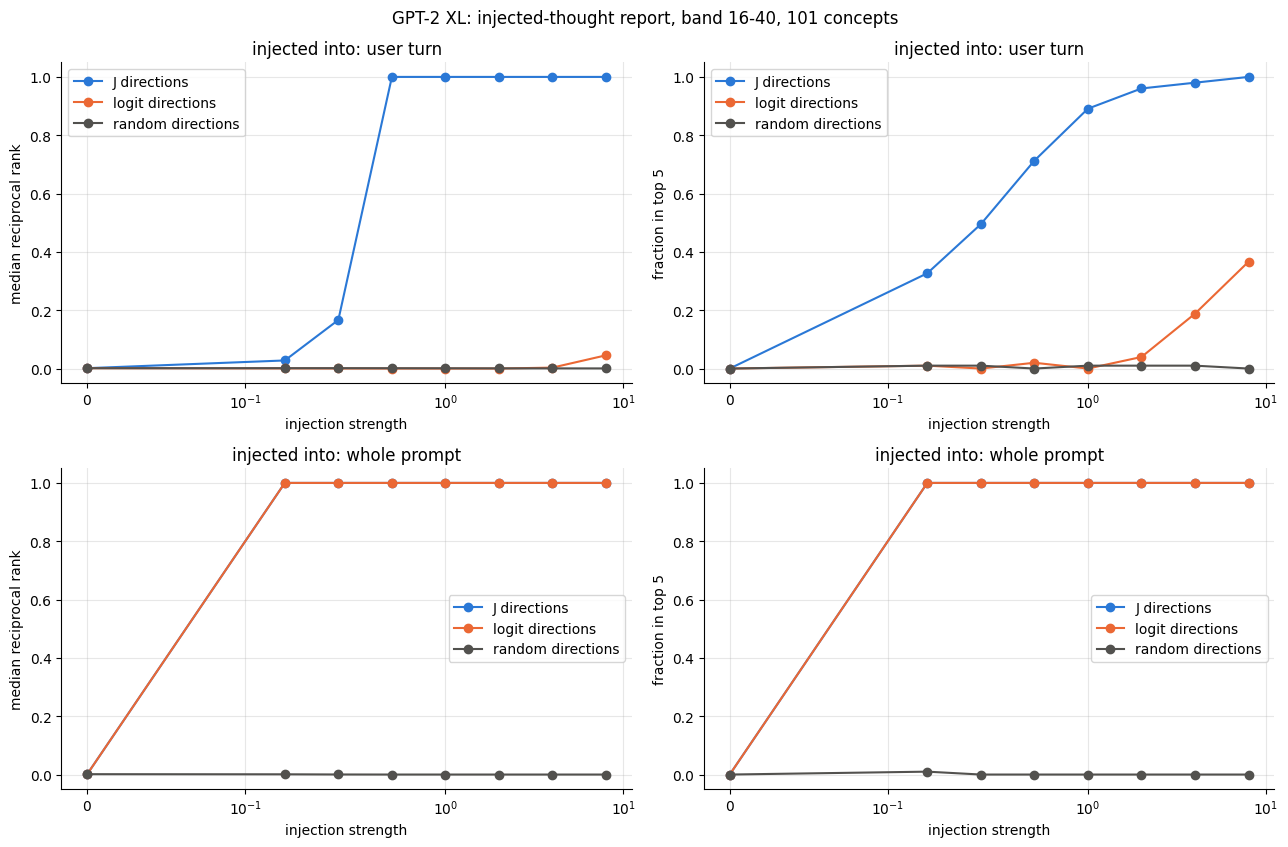

In [13]:
COLORS = {"J": "#2a78d6", "logit": "#eb6834", "random": "#52514e"}
fig, axes = plt.subplots(len(SPANS), 2, figsize=(13, 4.3 * len(SPANS)), squeeze=False)
for row, span in enumerate(SPANS):
    for mode, color in COLORS.items():
        picked = results[results["mode"].eq(mode) & results.band.eq(DEMO_BAND) & results.span.eq(span)]
        axes[row][0].plot(picked.groupby("strength").rr.median(), marker="o", color=color, label=f"{mode} directions")
        axes[row][1].plot(picked.groupby("strength").top5.mean(), marker="o", color=color, label=f"{mode} directions")
    for ax, label in zip(axes[row], ("median reciprocal rank", "fraction in top 5"), strict=True):
        ax.set_xlabel("injection strength")
        ax.set_ylabel(label)
        ax.set_xscale("symlog", linthresh=0.125)
        ax.set_title(f"injected into: {span}")
        ax.grid(alpha=0.3)
        ax.legend()
        ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"GPT-2 XL: injected-thought report, band {DEMO_BAND}, {len(concepts)} concepts")
fig.tight_layout()
plt.show()

### Does the control stay quiet?

In [14]:
ctrl = results[results.strength.eq(0.0)].drop_duplicates("concept")
print(f"control: named {ctrl.named.mean():.3f}, top-5 {ctrl.top5.mean():.3f}, "
      f"median rank {ctrl['rank'].median():.0f}")
display(ctrl.groupby("origin")["rank"].describe()[["count", "25%", "50%", "75%"]])
print("top-1 at the quote with nothing injected:", repr(ctrl.top1.iloc[0]))

control: named 0.000, top-5 0.000, median rank 767


,count,25%,50%,75%
origin,,,,
added,44.0,185.25,418.5,695.75
original,57.0,618.00,1255.0,2430.00


top-1 at the quote with nothing injected: 'love'


### Which concepts are reported, and what the model says instead

The J arm in the primary span and band at its strongest injection.

In [15]:
picked = results[results.span.eq(PRIMARY_SPAN) & results["mode"].eq("J") & results.band.eq(DEMO_BAND)
                 & results.strength.eq(max(STRENGTHS))].set_index("concept")
display(picked[["origin", "rank", "top1"]].sort_values("rank").head(10))
display(picked.top1.value_counts().head(8).to_frame("top-1 count"))

,origin,rank,top1
concept,,,
cook,original,1,cook
summary,original,1,summary
ox,original,1,ox
rust,original,1,rust
weight,original,1,weight
ear,original,1,ear
case,original,1,case
line,original,1,line
picture,original,1,picture


,top-1 count
top1,
cook,1
summary,1
ox,1
rust,1
weight,1
ear,1
case,1
line,1


## 5. Paired bootstrap intervals

Concept-clustered, with the three direction arms and the no-injection control of the same concept in
every draw. Computed from the cached trials; changing the bootstrap settings needs no model pass.

In [16]:
ci_table = introspection_bootstrap(results, **BOOTSTRAP_OPTIONS)
ci_table["analysis_role"] = "exploratory"
ci_table.loc[ci_table.span.eq(PRIMARY_SPAN) & ci_table.band.eq(DEMO_BAND), "analysis_role"] = "primary"

# The bootstrap keeps the plain equal-concept means as its point estimates.
means = results[results.strength.gt(0)].groupby(["span", "band", "strength", "mode"])[["named", "top5", "rr"]].mean()
arm_rows = ci_table[ci_table.statistic.eq("arm") & ci_table.arm.ne("control")]
for row in arm_rows.itertuples():
    assert abs(row.estimate - means.loc[(row.span, row.band, row.strength, row.arm), row.metric]) < 1e-12
ci_table.to_csv(RUN_DIR / "introspection_bootstrap.csv", index=False)
print(ci_table.status.value_counts().to_dict())


def ci_view(table):
    label = table.arm.where(table.statistic.eq("arm"), table.arm + " − " + table.reference)
    fmt = "{:.3g}".format
    cell = (table.estimate.map(fmt) + " [" + table.ci_low.map(fmt) + ", " + table.ci_high.map(fmt) + "]").where(
        table.status.eq("ok"), table.estimate.map(fmt) + " (" + table.status + ")")
    return table.assign(label=label, cell=cell).pivot(index="strength", columns="label", values="cell")


primary = ci_table[ci_table.analysis_role.eq("primary")]
for metric in ["named", "top5", "rr"]:
    print(f"primary setting ({PRIMARY_SPAN}, band {DEMO_BAND}): {metric}, "
          f"{100 * BOOTSTRAP_OPTIONS['confidence']:g}% CI, n={int(primary.n_units.iloc[0])} concepts")
    display(ci_view(primary[primary.metric.eq(metric)]))

{'ok': 888, 'degenerate': 876}
primary setting (user turn, band 16-40): named, 95% CI, n=101 concepts


label,J,J − control,J − logit,J − random,control,logit,random
strength,,,,,,,
0.125,"0.307 [0.218, 0.396]","0.307 [0.218, 0.396]","0.297 [0.208, 0.386]","0.307 [0.218, 0.396]",0 (degenerate),"0.0099 [0, 0.0297]",0 (degenerate)
0.250,"0.455 [0.356, 0.554]","0.455 [0.356, 0.554]","0.455 [0.356, 0.554]","0.455 [0.356, 0.554]",0 (degenerate),0 (degenerate),0 (degenerate)
0.500,"0.644 [0.554, 0.733]","0.644 [0.554, 0.733]","0.634 [0.545, 0.723]","0.644 [0.554, 0.733]",0 (degenerate),"0.0099 [0, 0.0297]",0 (degenerate)
1.000,"0.891 [0.832, 0.95]","0.891 [0.832, 0.95]","0.891 [0.832, 0.95]","0.891 [0.832, 0.95]",0 (degenerate),0 (degenerate),0 (degenerate)
2.000,"0.96 [0.921, 0.99]","0.96 [0.921, 0.99]","0.941 [0.891, 0.98]","0.96 [0.921, 0.99]",0 (degenerate),"0.0198 [0, 0.0495]",0 (degenerate)
4.000,"0.96 [0.921, 0.99]","0.96 [0.921, 0.99]","0.842 [0.762, 0.911]","0.96 [0.921, 0.99]",0 (degenerate),"0.119 [0.0594, 0.188]",0 (degenerate)
8.000,1 (degenerate),1 (degenerate),"0.762 [0.673, 0.842]",1 (degenerate),0 (degenerate),"0.238 [0.158, 0.327]",0 (degenerate)


primary setting (user turn, band 16-40): top5, 95% CI, n=101 concepts


label,J,J − control,J − logit,J − random,control,logit,random
strength,,,,,,,
0.125,"0.327 [0.238, 0.416]","0.327 [0.238, 0.416]","0.317 [0.228, 0.406]","0.317 [0.228, 0.406]",0 (degenerate),"0.0099 [0, 0.0297]","0.0099 [0, 0.0297]"
0.250,"0.495 [0.396, 0.594]","0.495 [0.396, 0.594]","0.495 [0.396, 0.594]","0.485 [0.386, 0.584]",0 (degenerate),0 (degenerate),"0.0099 [0, 0.0297]"
0.500,"0.713 [0.624, 0.802]","0.713 [0.624, 0.802]","0.693 [0.604, 0.782]","0.713 [0.624, 0.802]",0 (degenerate),"0.0198 [0, 0.0495]",0 (degenerate)
1.000,"0.891 [0.832, 0.95]","0.891 [0.832, 0.95]","0.891 [0.832, 0.95]","0.881 [0.812, 0.941]",0 (degenerate),0 (degenerate),"0.0099 [0, 0.0297]"
2.000,"0.96 [0.921, 0.99]","0.96 [0.921, 0.99]","0.921 [0.861, 0.97]","0.95 [0.901, 0.99]",0 (degenerate),"0.0396 [0.0099, 0.0792]","0.0099 [0, 0.0297]"
4.000,"0.98 [0.95, 1]","0.98 [0.95, 1]","0.792 [0.713, 0.871]","0.97 [0.931, 1]",0 (degenerate),"0.188 [0.119, 0.267]","0.0099 [0, 0.0297]"
8.000,1 (degenerate),1 (degenerate),"0.634 [0.535, 0.723]",1 (degenerate),0 (degenerate),"0.366 [0.277, 0.465]",0 (degenerate)


primary setting (user turn, band 16-40): rr, 95% CI, n=101 concepts


label,J,J − control,J − logit,J − random,control,logit,random
strength,,,,,,,
0.125,"0.329 [0.243, 0.418]","0.322 [0.238, 0.41]","0.312 [0.23, 0.399]","0.322 [0.237, 0.409]","0.00687 [0.00318, 0.0115]","0.0168 [0.00382, 0.0391]","0.00757 [0.00311, 0.014]"
0.250,"0.482 [0.39, 0.575]","0.475 [0.384, 0.568]","0.478 [0.387, 0.571]","0.474 [0.383, 0.568]","0.00687 [0.00318, 0.0115]","0.00327 [0.00116, 0.00603]","0.00737 [0.00305, 0.0138]"
0.500,"0.672 [0.583, 0.757]","0.665 [0.577, 0.749]","0.657 [0.569, 0.743]","0.666 [0.578, 0.751]","0.00687 [0.00318, 0.0115]","0.0142 [0.000705, 0.04]","0.00526 [0.00262, 0.00895]"
1.000,"0.895 [0.835, 0.952]","0.888 [0.827, 0.945]","0.892 [0.832, 0.949]","0.89 [0.829, 0.947]","0.00687 [0.00318, 0.0115]","0.00241 [0.000307, 0.00557]","0.0046 [0.00201, 0.00909]"
2.000,"0.962 [0.922, 0.991]","0.955 [0.915, 0.986]","0.935 [0.887, 0.976]","0.957 [0.917, 0.989]","0.00687 [0.00318, 0.0115]","0.0263 [0.00373, 0.0565]","0.00481 [0.00124, 0.0116]"
4.000,"0.967 [0.931, 0.993]","0.96 [0.924, 0.987]","0.808 [0.735, 0.875]","0.964 [0.928, 0.991]","0.00687 [0.00318, 0.0115]","0.158 [0.0986, 0.225]","0.003 [0.000852, 0.0071]"
8.000,1 (degenerate),"0.993 [0.988, 0.997]","0.697 [0.615, 0.775]","0.998 [0.996, 0.999]","0.00687 [0.00318, 0.0115]","0.303 [0.225, 0.385]","0.00191 [0.000677, 0.00421]"


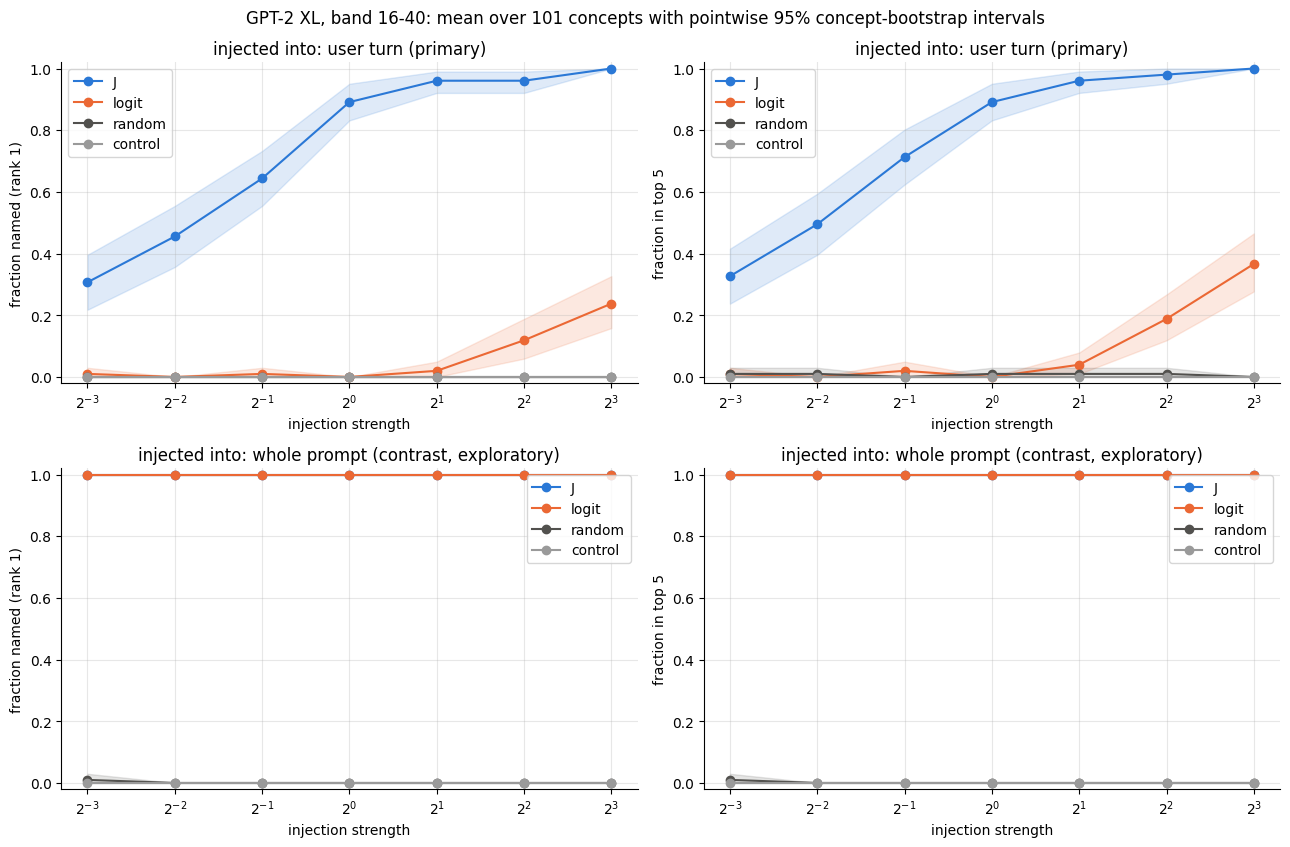

In [17]:
ARM_COLORS = {**COLORS, "control": "#9a9a9a"}
fig, axes = plt.subplots(len(SPANS), 2, figsize=(13, 4.3 * len(SPANS)), squeeze=False)
for row, span in enumerate(SPANS):
    for column, metric in enumerate(["named", "top5"]):
        ax = axes[row][column]
        table = ci_table[ci_table.span.eq(span) & ci_table.band.eq(DEMO_BAND) & ci_table.metric.eq(metric)
                         & ci_table.statistic.eq("arm")]
        for arm, color in ARM_COLORS.items():
            line = table[table.arm.eq(arm)].sort_values("strength")
            ok = line.status.eq("ok")
            ax.plot(line.strength, line.estimate, marker="o", color=color, label=arm)
            ax.fill_between(line.strength, line.ci_low.where(ok, line.estimate),
                            line.ci_high.where(ok, line.estimate), color=color, alpha=0.15)
        ax.set_xscale("log", base=2)
        ax.set_ylim(-0.02, 1.02)
        ax.set_xlabel("injection strength")
        ax.set_ylabel({"named": "fraction named (rank 1)", "top5": "fraction in top 5"}[metric])
        role = "primary" if span == PRIMARY_SPAN else "contrast, exploratory"
        ax.set_title(f"injected into: {span} ({role})")
        ax.grid(alpha=0.3)
        ax.legend()
        ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"GPT-2 XL, band {DEMO_BAND}: mean over {len(concepts)} concepts with pointwise "
             f"{100 * BOOTSTRAP_OPTIONS['confidence']:g}% concept-bootstrap intervals")
fig.tight_layout()
plt.show()

### Paired differences in the primary setting

J − random is the specificity of the J-lens direction over a perturbation of the same size, and
J − control is the effect of injecting at all. Both must exclude zero for a positive claim.

In [18]:
diffs = primary[primary.statistic.eq("difference") & primary.metric.isin(["named", "top5"])]
display(diffs.pivot_table(index=["metric", "strength"], columns=["arm", "reference"],
                          values=["estimate", "ci_low", "ci_high"], dropna=False).round(3))

ci_high                ci_low               estimate              
arm                   J                     J                      J              
reference       control  logit random control  logit random  control  logit random
metric strength                                                                   
named  0.125      0.396  0.386  0.396   0.218  0.208  0.218    0.307  0.297  0.307
       0.250      0.554  0.554  0.554   0.356  0.356  0.356    0.455  0.455  0.455
       0.500      0.733  0.723  0.733   0.554  0.545  0.554    0.644  0.634  0.644
       1.000      0.950  0.950  0.950   0.832  0.832  0.832    0.891  0.891  0.891
       2.000      0.990  0.980  0.990   0.921  0.891  0.921    0.960  0.941  0.960
       4.000      0.990  0.911  0.990   0.921  0.762  0.921    0.960  0.842  0.960
       8.000        NaN  0.842    NaN     NaN  0.673    NaN    1.000  0.762  1.000
top5   0.125      0.416  0.406  0.406   0.238  0.228  0.228    0.327  0.317  0.317
       0.250      0.594  0.594  0.584   0.396  0.396  0.386    0.495  0.495  0.485
       0.500      0.802  0.782  0.802   0.624  0.604  0.624    0.713  0.693  0.713
       1.000      0.950  0.950  0.941   0.832  0.832  0.812    0.891  0.891  0.881
       2.000      0.990  0.970  0.990   0.921  0.861  0.901    0.960  0.921  0.950
       4.000      1.000  0.871  1.000   0.950  0.713  0.931    0.980  0.792  0.970
       8.000        NaN  0.723    NaN     NaN  0.535    NaN    1.000  0.634  1.000

### By concept origin

Kept originals vs added nouns, in the primary setting, each bootstrapped over its own concepts.

In [19]:
primary_results = results[results.span.eq(PRIMARY_SPAN) & results.band.eq(DEMO_BAND)]
by_origin = introspection_bootstrap(primary_results, keys=["span", "band", "strength", "origin"],
                                    **BOOTSTRAP_OPTIONS)
picked = by_origin[by_origin.metric.eq("top5") & by_origin.statistic.eq("arm")]
display(picked.pivot_table(index=["origin", "strength"], columns="arm",
                           values=["estimate", "ci_low", "ci_high"], dropna=False).round(3))

ci_high                       ci_low                       estimate                      
arm                     J control  logit random      J control  logit random        J control  logit random
origin   strength                                                                                          
added    0.125      0.591     NaN  0.068  0.068  0.318     NaN  0.000    0.0    0.455     0.0  0.023  0.023
         0.250      0.705     NaN    NaN  0.068  0.409     NaN    NaN    0.0    0.568     0.0  0.000  0.023
         0.500      0.864     NaN  0.114    NaN  0.614     NaN  0.000    NaN    0.750     0.0  0.045  0.000
         1.000      0.977     NaN    NaN  0.068  0.818     NaN    NaN    0.0    0.909     0.0  0.000  0.023
         2.000      1.000     NaN  0.159  0.068  0.932     NaN  0.000    0.0    0.977     0.0  0.068  0.023
         4.000      1.000     NaN  0.364  0.068  0.932     NaN  0.114    0.0    0.977     0.0  0.227  0.023
         8.000        NaN     NaN  0.501    NaN    NaN     NaN  0.227    NaN    1.000     0.0  0.364  0.000
original 0.125      0.333     NaN    NaN    NaN  0.123     NaN    NaN    NaN    0.228     0.0  0.000  0.000
         0.250      0.579     NaN    NaN    NaN  0.316     NaN    NaN    NaN    0.439     0.0  0.000  0.000
         0.500      0.807     NaN    NaN    NaN  0.561     NaN    NaN    NaN    0.684     0.0  0.000  0.000
         1.000      0.947     NaN    NaN    NaN  0.789     NaN    NaN    NaN    0.877     0.0  0.000  0.000
         2.000      1.000     NaN  0.053    NaN  0.877     NaN  0.000    NaN    0.947     0.0  0.018  0.000
         4.000      1.000     NaN  0.263    NaN  0.947     NaN  0.070    NaN    0.982     0.0  0.158  0.000
         8.000        NaN     NaN  0.491    NaN    NaN     NaN  0.246    NaN    1.000     0.0  0.368  0.000

## 6. Conclusions

* **Primary setting (user turn, band 16–40).** The J arm names the concept in 31% [22, 40] of trials at
  strength 0.125, 46% [36, 55] at 0.25, 64% [55, 73] at 0.5, 89% [83, 95] at 1, 96% [92, 99] at 2 and 4, and
  100% at 8 (pointwise 95% concept-bootstrap intervals, n = 101). Logit directions name it in 0–2% up to
  strength 2, 12% at 4 and 24% at 8; random directions never. J − logit is +0.30 [0.21, 0.39] at 0.125 and
  +0.94 [0.89, 0.98] at 2.
* **Only the lowest strengths are small perturbations.** Even at a fixed scale the additions of 24 layers add
  up: after layer 39 the question-turn residual is 1.2× its clean norm at strength 0.125, 9.5× at 1 and 77× at
  8. The effect is already 31% where the residual is barely changed.
* **The control is clean.** With nothing injected no concept is named or in the top 5 (median rank 767; the
  unprompted answer is `"love"`). The added nouns sit closer to the top (median control rank 418 vs 1255) and
  are named more often at the lowest strength (45% vs 23% at 0.125), so the two origins should be reported
  separately; at strength 1 they reach 91% and 88%.
* **J beats logit in early and middle bands, as for the swaps.** At strength 1 the J arm names 89% in 16–40,
  80% in 32–40, 73% in 40–47, 42% in 24–32, 18% in 16–24 and 4% in 8–16 (the narrow early bands reach 74% and
  53% at strength 4). Logit directions name at most 3% in 8–16 at any strength and at most 1% in 16–24
  below strength 8, but 30–66% in 32–47 at strength 1, where J and logit directions converge (mean cosine 0.28 at
  layer 0 to 0.90 at layer 42). This matches `concept_swap.ipynb`.
* **The whole-prompt arm is output steering.** It includes the readout position, so J and logit directions
  are at ≥ 98% from strength 0.125 (logit in 8–16: 50%) and random directions at 0–1%.
* **This is not shown to be introspection.** The prefill asserts detection, so only identification is scored,
  and at strength ≥ 1 the continuation is the injected word repeated. A base model copying a word that its
  residuals encode at earlier positions explains the result without self-report.
* **Next checks.** Continuations at strengths 0.125–0.5, where the residual is nearly unchanged; a
  neutral-prompt control (the same injection over a question without the introspection framing) to separate
  report from priming; a detection arm without the forced `Yes`. The J-space / non-J-space decomposition of
  the paper's Figure 8 is in `jspace_decomposition.ipynb`.

**Run.** `openai-community/gpt2-xl` (revision 15ea56de) in fp32, `<|endoftext|>` as BOS; lens
`gpt2-xl_jacobian_lens.pt` fitted on 339 WikiText-103 prompts × 128 tokens (Neuronpedia recipe,
`wikitext_lens_fit.ipynb`); prefill `word`; 101 concepts of `verbal-introspection-gpt2.json`; injection scaled
by the clean mean residual norm over the span at each layer; 256 trials per pass. One V100-SXM3-32GB: 108
forward passes in 13 minutes.